# 变分积分器求解匀速圆周运动

- [周详](xiangzhou@whu.edu.cn)
- 武汉大学
- 2026年9月28日

例 2（简谐振子）与例 3（单摆）把变分积分器的两级"能量保证"演示完了：二次型 ⟹ 严格恒等；非线性 ⟹ $O(h^2)$ 有界带宽。本例把舞台升到二维：**匀速圆周运动**——它在直角坐标下是两个互相垂直的简谐振子，能量仍是二次型，却多出一个新的守恒量：**角动量**。

第二章的故事线：第二章例 1 中前向欧拉法在直角坐标下螺旋外扩（末半径 $3.32$）；第二章例 6 中 RK2 保住了圆的形状、却让半径与角动量按同一解析律 $E_n = E_0(1+z^4/4)^n$ 缓慢膨胀（$48$ s 末 $\times 1.0015$）。变分积分器呢？

二维各向同性振子的拉格朗日量（$\boldsymbol q = (x, y)$，$\omega_0 = \sqrt{k/m}$，$z = \omega_0 h$）：

$$
L = \tfrac{1}{2}m|\dot{\boldsymbol q}|^2 - \tfrac{1}{2}k|\boldsymbol q|^2
$$

中点离散拉格朗日量 $L_d = h\,L(\tfrac{\boldsymbol q_k + \boldsymbol q_{k+1}}{2}, \tfrac{\Delta\boldsymbol q}{h})$ 代入离散变分原理，DEL 为**向量方程**——且由于各向同性，它与例 2 的标量方程**逐分量相同**：

$$
q_{i,k+1} = 2c\,q_{i,k} - q_{i,k-1}, \qquad
c = \frac{1 - z^2/4}{1 + z^2/4} = \cos\theta, \quad \theta = 2\arctan\frac{z}{2}, \quad i = x, y
$$

两个分量以**同一角度** $\theta$ 旋转——$(x_k, y_k)$ 在平面上走出一个**严格的圆**。启动步与节点动量同例 2（逐分量）：

$$
\boldsymbol q_1 = \frac{\boldsymbol q_0(1 - z^2/4) + h\boldsymbol v_0}{1 + z^2/4},
\qquad
\boldsymbol v_k = \frac{\boldsymbol q_{k+1} - \boldsymbol q_k}{h} + \frac{\omega_0^2 h}{4}(\boldsymbol q_k + \boldsymbol q_{k+1})
$$

参数与第二章例 6 完全一致：$m = k = 1$，$\omega_0 = 1$，$R = 1$，$\boldsymbol q_0 = (1, 0)$，$\boldsymbol v_0 = (0, 1)$，$h = 0.05$ s（$z = 0.05$），$t = 48$ s ≈ $7.6$ 圈；$E_0 = 1$ J，$L_0 = m R^2\omega_0 = 1$ kg·m²/s。

**运行之前，先把你的预测写下来**：

1. 轨迹还是圆吗？半径会像 RK2 那样每步膨胀 $\times\sqrt{1+z^4/4}$（$48$ s 末 $1.00075$）、像欧拉那样螺旋到 $3.32$ 吗，还是……？
2. 第二章例 6 发现 RK2 的**能量与角动量按同一律膨胀**。变分积分器的 $E$ 与 $L$ 会怎样？
3. 钟：例 2 的变分积分器是慢钟（$-z^2/12$）、RK2 是快钟（$+z^2/6$）。$7.6$ 圈下来，两种方法各落后/领先多少弧度？

带着预测运行下面的代码，逐条对照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 字体配置：按操作系统自动选择中文字体，
# 西文与数学公式用 Times New Roman 风格（STIX）
import platform
system = platform.system()
if system == 'Darwin':
    cn_font = 'Songti SC'
elif system == 'Windows':
    cn_font = 'SimSun'
else:  # Linux
    cn_font = 'Noto Serif CJK SC'

plt.rcParams['font.family'] = [cn_font, 'Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
def variational_circular(q0, v0, k, m, h, n_steps):
    """变分积分器（中点 L_d）求解二维各向同性振子（匀速圆周运动）
    DEL 逐分量：q_{i,k+1} = 2c q_{i,k} - q_{i,k-1}，c = (1-z^2/4)/(1+z^2/4)
    返回时间、位置数组 (n+1, 2)、速度数组 (n+1, 2)"""
    om0 = np.sqrt(k / m)
    z = om0 * h
    c = (1 - z**2 / 4) / (1 + z**2 / 4)
    t = np.arange(n_steps + 1) * h
    q = np.empty((n_steps + 2, 2))
    q[0] = q0
    q[1] = (q0 * (1 - z**2 / 4) + h * v0) / (1 + z**2 / 4)   # 由 p_0 = m v_0 反解
    for j in range(1, n_steps + 1):
        q[j + 1] = 2 * c * q[j] - q[j - 1]   # DEL 递推：平面纯旋转
    v = (q[1:] - q[:-1]) / h + (om0**2 * h / 4) * (q[1:] + q[:-1])   # p_k / m
    return t, q[:-1].copy(), v


def rk2_midpoint_cart(q0, v0, k, m, h, n_steps):
    """RK2 中点法求解二维振子（第二章例 6 原格式）"""
    t = np.arange(n_steps + 1) * h
    q = np.empty((n_steps + 1, 2))
    v = np.empty((n_steps + 1, 2))
    q[0], v[0] = q0, v0
    for n in range(n_steps):
        v_mid = v[n] - 0.5 * h * (k / m) * q[n]
        q_mid = q[n] + 0.5 * h * v[n]
        q[n + 1] = q[n] + h * v_mid
        v[n + 1] = v[n] - h * (k / m) * q_mid
    return t, q, v


def forward_euler_cart(q0, v0, k, m, h, n_steps):
    """前向欧拉法求解二维振子（第二章例 1 原格式）"""
    t = np.arange(n_steps + 1) * h
    q = np.empty((n_steps + 1, 2))
    v = np.empty((n_steps + 1, 2))
    q[0], v[0] = q0, v0
    for n in range(n_steps):
        v[n + 1] = v[n] - h * (k / m) * q[n]
        q[n + 1] = q[n] + h * v[n]
    return t, q, v


def energy_circ(q, v):
    return 0.5 * m * np.sum(v**2, axis=1) + 0.5 * k * np.sum(q**2, axis=1)


def angmom(q, v):
    return m * (q[:, 0] * v[:, 1] - q[:, 1] * v[:, 0])


# 参数（与第二章例 6 完全一致）
k, m = 1.0, 1.0
om0 = np.sqrt(k / m)
q0, v0 = np.array([1.0, 0.0]), np.array([0.0, 1.0])
h = 0.05
t_end = 48.0
n_steps = int(t_end / h)
z = om0 * h
E0 = energy_circ(q0[None, :], v0[None, :])[0]
L0 = angmom(q0[None, :], v0[None, :])[0]
theta_step = 2 * np.arctan(z / 2)

t, q_vi, v_vi = variational_circular(q0, v0, k, m, h, n_steps)
_, q_rk, v_rk = rk2_midpoint_cart(q0, v0, k, m, h, n_steps)
_, q_eu, v_eu = forward_euler_cart(q0, v0, k, m, h, n_steps)

r_vi = np.sqrt(np.sum(q_vi**2, axis=1))
r_rk = np.sqrt(np.sum(q_rk**2, axis=1))
r_eu = np.sqrt(np.sum(q_eu**2, axis=1))
phi_true = np.arctan2(q0[1], q0[0]) + om0 * t
phi_vi = np.unwrap(np.arctan2(q_vi[:, 1], q_vi[:, 0]))
phi_rk = np.unwrap(np.arctan2(q_rk[:, 1], q_rk[:, 0]))
phi_eu = np.unwrap(np.arctan2(q_eu[:, 1], q_eu[:, 0]))

print(f'z = {z}，每步旋转角 θ = 2 arctan(z/2) = {theta_step:.10f} rad（比 z 慢 {z - theta_step:.2e}）')
print(f'{"":22}{"变分积分器":>18}{"RK2":>14}{"前向欧拉":>12}')
print(f'{"末半径":22}{r_vi[-1]:>18.12f}{r_rk[-1]:>14.6f}{r_eu[-1]:>12.4f}')
print(f'{"|r - 1| 最大":22}{np.abs(r_vi - 1).max():>18.1e}{np.abs(r_rk - 1).max():>14.2e}{np.abs(r_eu - 1).max():>12.2e}')
print(f'{"末能量 E/E0":22}{energy_circ(q_vi, v_vi)[-1] / E0:>18.12f}{energy_circ(q_rk, v_rk)[-1] / E0:>14.8f}{energy_circ(q_eu, v_eu)[-1] / E0:>12.4f}')
print(f'{"理论 E/E0":22}{"（严格 = 1）":>18}{(1 + z**4 / 4)**n_steps:>14.8f}{(1 + z**2)**n_steps:>12.4f}')
print(f'{"末角动量 L/L0":22}{angmom(q_vi, v_vi)[-1] / L0:>18.12f}{angmom(q_rk, v_rk)[-1] / L0:>14.8f}{angmom(q_eu, v_eu)[-1] / L0:>12.4f}')
print(f'\n累计角度误差（48 s，7.6 圈）：')
print(f'  变分积分器：{phi_vi[-1] - phi_true[-1]:+.6f} rad（理论 -n·z^3/12 = {-n_steps * (z - theta_step):+.6f}，慢钟）')
print(f'  RK2       ：{phi_rk[-1] - phi_true[-1]:+.6f} rad（理论 +n·z^3/6 = {+n_steps * (np.arctan(z / (1 - z**2 / 2)) - z):+.6f}，快钟）')
print(f'  前向欧拉  ：{phi_eu[-1] - phi_true[-1]:+.4f} rad（半径失守的连锁反应）')

z = 0.05，每步旋转角 θ = 2 arctan(z/2) = 0.0499895872 rad（比 z 慢 1.04e-05）
                                   变分积分器           RK2        前向欧拉
末半径                       1.000000000000      1.000750      3.3151
|r - 1| 最大                       6.1e-14      7.50e-04    2.32e+00
末能量 E/E0                  1.000000000000    1.00150112     10.9902
理论 E/E0                         （严格 = 1）    1.00150112     10.9902
末角动量 L/L0                 1.000000000000    1.00150112     10.9902

累计角度误差（48 s，7.6 圈）：
  变分积分器：-0.009996 rad（理论 -n·z^3/12 = -0.009996，慢钟）
  RK2       ：+0.019985 rad（理论 +n·z^3/6 = +0.019985，快钟）
  前向欧拉  ：-0.0399 rad（半径失守的连锁反应）


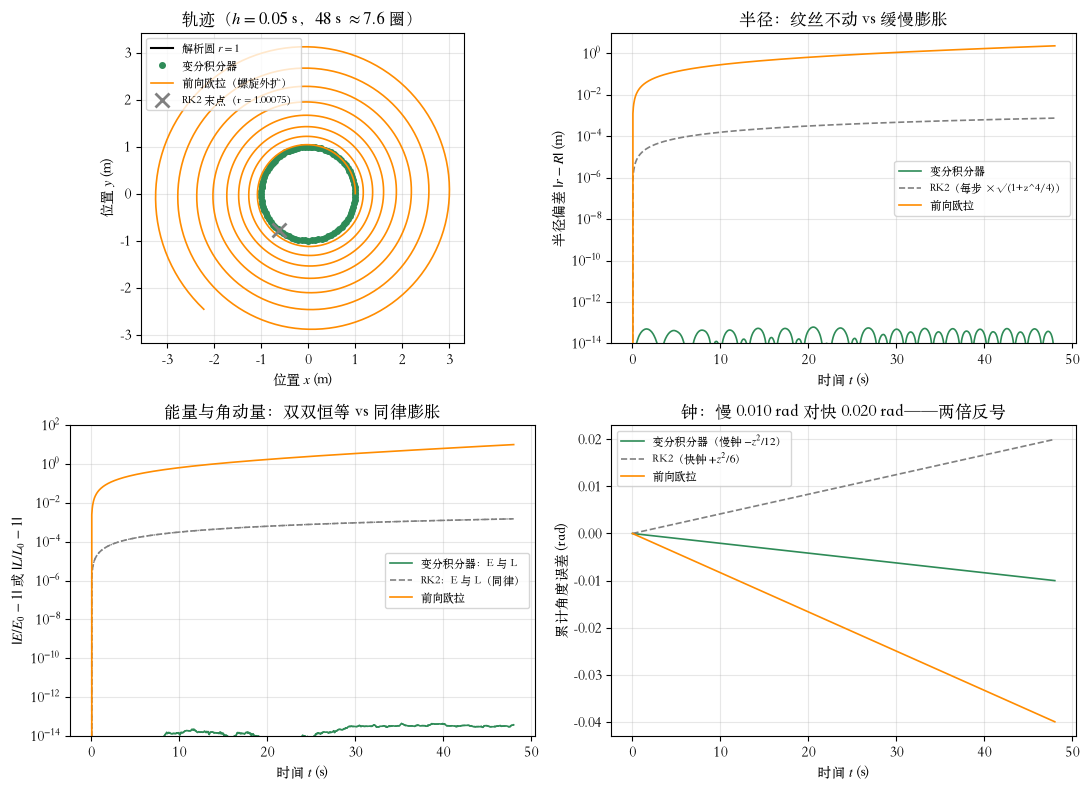

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))

# (a) 轨迹：变分积分器严格在圆上，欧拉螺旋外扩
ax = axs[0, 0]
th_c = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(th_c), np.sin(th_c), '-', color='black', lw=1.5, label='解析圆 $r = 1$')
ax.plot(q_vi[:, 0], q_vi[:, 1], 'o', color='seagreen', ms=4, markevery=10, label='变分积分器')
ax.plot(q_eu[:, 0], q_eu[:, 1], '-', color='darkorange', lw=1.2, label='前向欧拉（螺旋外扩）')
ax.plot(q_rk[-1, 0], q_rk[-1, 1], 'x', color='gray', ms=10, mew=2,
        label=f'RK2 末点（r = {r_rk[-1]:.5f}）')
ax.set_xlabel('位置 $x$ (m)')
ax.set_ylabel('位置 $y$ (m)')
ax.set_title('轨迹（$h = 0.05$ s，$48$ s $\\approx 7.6$ 圈）')
ax.set_aspect('equal')
ax.legend(fontsize=8, loc='upper left')
ax.grid(alpha=0.3)

# (b) 半径偏差（对数纵轴）
ax = axs[0, 1]
ax.semilogy(t, np.abs(r_vi - 1) + 1e-300, '-', color='seagreen', lw=1.2, label='变分积分器')
ax.semilogy(t, np.abs(r_rk - 1), '--', color='gray', lw=1.2, label='RK2（每步 ×√(1+z^4/4)）')
ax.semilogy(t, np.abs(r_eu - 1), '-', color='darkorange', lw=1.2, label='前向欧拉')
ax.set_ylim(1e-14, 1e1)
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('半径偏差 $|r - R|$ (m)')
ax.set_title('半径：纹丝不动 vs 缓慢膨胀')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

# (c) 能量与角动量（对数纵轴）：RK2 两条曲线重合
ax = axs[1, 0]
ax.semilogy(t, np.abs(energy_circ(q_vi, v_vi) / E0 - 1) + 1e-300, '-', color='seagreen', lw=1.2, label='变分积分器：E 与 L')
ax.semilogy(t, np.abs(angmom(q_vi, v_vi) / L0 - 1) + 1e-300, '--', color='seagreen', lw=1.0)
ax.semilogy(t, np.abs(energy_circ(q_rk, v_rk) / E0 - 1), '--', color='gray', lw=1.2, label='RK2：E 与 L（同律）')
ax.semilogy(t, np.abs(angmom(q_rk, v_rk) / L0 - 1), ':', color='gray', lw=1.0)
ax.semilogy(t, np.abs(energy_circ(q_eu, v_eu) / E0 - 1), '-', color='darkorange', lw=1.2, label='前向欧拉')
ax.set_ylim(1e-14, 1e2)
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('$|E/E_0 - 1|$ 或 $|L/L_0 - 1|$')
ax.set_title('能量与角动量：双双恒等 vs 同律膨胀')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

# (d) 累计角度误差：钟慢对钟快
ax = axs[1, 1]
ax.plot(t, phi_vi - phi_true, '-', color='seagreen', lw=1.2, label='变分积分器（慢钟 $-z^2/12$）')
ax.plot(t, phi_rk - phi_true, '--', color='gray', lw=1.2, label='RK2（快钟 $+z^2/6$）')
ax.plot(t, phi_eu - phi_true, '-', color='darkorange', lw=1.2, label='前向欧拉')
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('累计角度误差 (rad)')
ax.set_title('钟：慢 0.010 rad 对快 0.020 rad——两倍反号')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig('outputs/4_circular_variational.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**对照预测 1–3**：

- **轨迹是严格的圆**：$|r - 1|$ 最大 $6\times 10^{-14}$ m——纯舍入。RK2 末半径 $1.000750$（每步 $\times\sqrt{1+z^4/4}$，第二章例 6 的律逐位兑现），欧拉螺旋到 $3.32$。同一个坐标（直角）、同一个步长，三种方法的命运全写在几何性质里。
- **$E$ 与 $L$ 双双恒等**：变分积分器 $E/E_0 = 1 + O(10^{-14})$、$L/L_0 = 1 + O(10^{-14})$；RK2 的 $E$ 与 $L$ **双双** $\times 1.00150112$——与 $(1+z^4/4)^{960}$ 逐位一致（第二章例 6 发现的"同律"原样重现）；欧拉 $\times 10.99$。
- **钟慢 $0.0100$ rad，钟快 $0.0200$ rad**：变分积分器 $48$ s 落后 $-n z^3/12 = -0.0100$ rad（逐位符合），RK2 领先 $+n z^3/6 = +0.0200$ rad——例 2 的"$-z^2/12$ 对 $+z^2/6$、两倍反号"在二维原样上演。欧拉也是慢钟（$-n z^3/3 = -0.040$ rad）——但它的半径早已失守，角度准已无意义。

## 为什么：一个旋转，三个不变量

- **各向同性 ⟹ 平面纯旋转**。$x$、$y$ 两个分量满足**同一个**递推（同一 $c$、同一 $\theta$），所以 $(x_k, y_k)$ 是初始向量旋转 $k\theta$ 的结果——半径、能量、角动量是旋转的三个不变量，全部**严格守恒**（例 2 恒等式的二维推广；能量仍是二次型，特权延续）。
- **与第二章例 6 对照**。RK2 在这里的表现其实不差：各向同性让它的膨胀"温和"——圆还是圆，只是半径与 $E$、$L$ 一起按 $1+z^4/4$ 慢慢胀。变分积分器把这份"温和"升级为"没有"：半径一分不涨，$E$、$L$ 一分不动。
- **钟慢是家族印记**。$\theta = 2\arctan(z/2) = z - z^3/12 + \cdots$——中点 $L_d$ 家族的慢钟（例 2 已见）；RK2 的快钟 $+z^3/6$ 恰为两倍、反号。注意角度误差 $\propto z^3 t$ 是**三阶小量**：$z = 0.05$ 时 $48$ s 才积累 $0.01$ rad。
- **极坐标的故事依旧**（第二章例 1、第二章例 6 的坐标主题）：在极坐标 $(r, \theta)$ 下，常半径序列 $r_k \equiv R$、$\theta_k = \theta_0 + k\omega_0 h$ **精确满足**极坐标 DEL——因为每步的"力平衡" $mR\omega_0^2 = kR$ 让方程两侧同时归零，与离散化的细节无关。精确性由坐标裁决；而 $\theta$ 是循环坐标，离散 Noether 定理保证 $p_\theta$ **严格守恒**（下一节在直角坐标里演示它的身影——角动量正是旋转对称性的 Noether 荷）。

## 追问：换椭圆轨道——Noether 的离散礼物

圆轨道是特例。把初速度减半，$\boldsymbol v_0 = (0, 0.5)$（即 $0.5\omega_0 R$）：轨迹变成半长轴 $a = 1$、半短轴 $b = 0.5$ 的**椭圆**。此时旋转对称性还在（势能仍是各向同性的 $\tfrac12 k|\boldsymbol q|^2$），Noether 定理说角动量守恒；离散版的定理更强：

> **任何**变分积分器、**任何**步长，只要离散拉格朗日量继承连续系统的对称性，对应的**离散动量映射精确守恒**。

**先预测，再运行**：

1. 变分积分器的 $E$ 与 $L$ 还恒等吗？RK2 呢（第二章例 6 说 $E$、$L$ 同律膨胀——椭圆上还成立吗）？
2. 椭圆本身的形状准吗（半长轴、半短轴与解析值差多少）？

椭圆轨道（a = 1, b = 0.5，E0 = 0.625 J，L0 = 0.5 kg·m²/s）：
  变分积分器：max|E/E0 - 1| = 1.2e-13，max|L/L0 - 1| = 4.4e-14
  RK2       ：E/E0 末 = 1.00150112，L/L0 末 = 1.00150112（理论 (1+z^4/4)^n = 1.00150112）
  变分积分器椭圆：半长轴 max r = 1.0000000000（解析 1），半短轴 min r = 0.5000014（解析 0.5）


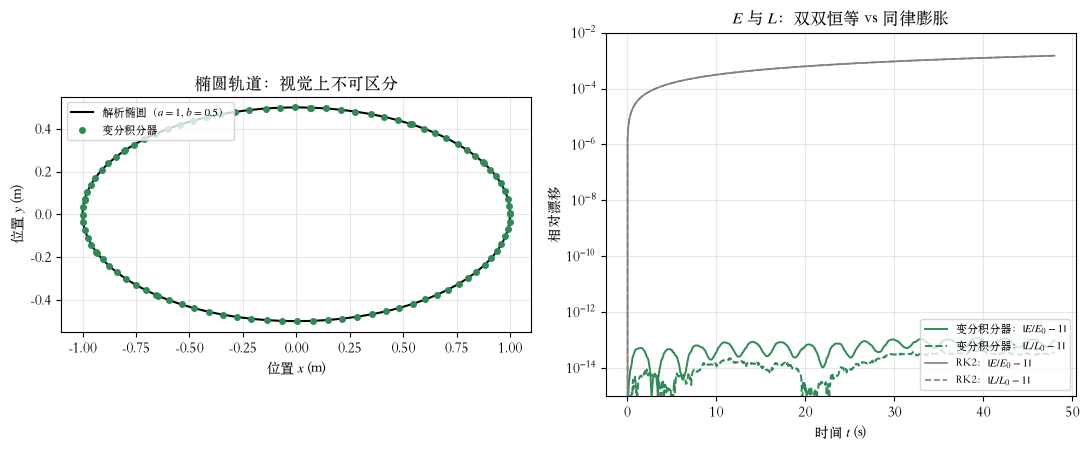

In [4]:
vy0_e = 0.5                       # 椭圆轨道：初速度减半
q0_e, v0_e = np.array([1.0, 0.0]), np.array([0.0, vy0_e])
E0e = energy_circ(q0_e[None, :], v0_e[None, :])[0]
L0e = angmom(q0_e[None, :], v0_e[None, :])[0]

t, q_vi_e, v_vi_e = variational_circular(q0_e, v0_e, k, m, h, n_steps)
_, q_rk_e, v_rk_e = rk2_midpoint_cart(q0_e, v0_e, k, m, h, n_steps)
Ee_vi, Le_vi = energy_circ(q_vi_e, v_vi_e), angmom(q_vi_e, v_vi_e)
Ee_rk, Le_rk = energy_circ(q_rk_e, v_rk_e), angmom(q_rk_e, v_rk_e)
r_ell = np.sqrt(np.sum(q_vi_e**2, axis=1))

print(f'椭圆轨道（a = 1, b = {vy0_e / om0}，E0 = {E0e} J，L0 = {L0e} kg·m²/s）：')
print(f'  变分积分器：max|E/E0 - 1| = {np.abs(Ee_vi / E0e - 1).max():.1e}，max|L/L0 - 1| = {np.abs(Le_vi / L0e - 1).max():.1e}')
print(f'  RK2       ：E/E0 末 = {Ee_rk[-1] / E0e:.8f}，L/L0 末 = {Le_rk[-1] / L0e:.8f}（理论 (1+z^4/4)^n = {(1 + z**4 / 4)**n_steps:.8f}）')
print(f'  变分积分器椭圆：半长轴 max r = {r_ell.max():.10f}（解析 1），半短轴 min r = {r_ell.min():.7f}（解析 {vy0_e / om0}）')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))

# (a) 椭圆轨迹：变分积分器 vs 解析椭圆
ax1.plot(np.cos(th_c), vy0_e / om0 * np.sin(th_c), '-', color='black', lw=1.5, label='解析椭圆（$a = 1$, $b = 0.5$）')
ax1.plot(q_vi_e[:, 0], q_vi_e[:, 1], 'o', color='seagreen', ms=4, markevery=10, label='变分积分器')
ax1.set_xlabel('位置 $x$ (m)')
ax1.set_ylabel('位置 $y$ (m)')
ax1.set_title('椭圆轨道：视觉上不可区分')
ax1.set_aspect('equal')
ax1.legend(fontsize=8, loc='upper left')
ax1.grid(alpha=0.3)

# (b) E 与 L 的漂移（对数纵轴）
ax2.semilogy(t, np.abs(Ee_vi / E0e - 1) + 1e-300, '-', color='seagreen', lw=1.4, label='变分积分器：$|E/E_0 - 1|$')
ax2.semilogy(t, np.abs(Le_vi / L0e - 1) + 1e-300, '--', color='seagreen', lw=1.4, label='变分积分器：$|L/L_0 - 1|$')
ax2.semilogy(t, np.abs(Ee_rk / E0e - 1), '-', color='gray', lw=1.2, label='RK2：$|E/E_0 - 1|$')
ax2.semilogy(t, np.abs(Le_rk / L0e - 1), '--', color='gray', lw=1.2, label='RK2：$|L/L_0 - 1|$')
ax2.set_ylim(1e-15, 1e-2)
ax2.set_xlabel('时间 $t$ (s)')
ax2.set_ylabel('相对漂移')
ax2.set_title('$E$ 与 $L$：双双恒等 vs 同律膨胀')
ax2.legend(fontsize=8, loc='lower right')
ax2.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig('outputs/4_circular_variational_elliptic.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**读图**：

- **双恒等**：变分积分器 $|E/E_0 - 1| \sim 10^{-13}$、$|L/L_0 - 1| \sim 10^{-14}$——能量与角动量同时钉死在机器精度。两个恒等的**来源不同**：$E$ 靠二次型特权（各向同性振子的能量是二次型，例 2 的 Cayley 恒等式照搬）；$L$ 靠**离散 Noether**——旋转对称性的动量映射，**不需要**二次型，任何变分积分器、任何步长都精确守恒。
- **RK2 的"同律"在椭圆上依旧**：$E$ 与 $L$ 双双 $\times 1.00150112 = (1+z^4/4)^{960}$——第二章例 6 在圆轨道上发现的解析律原样成立。
- **形状差 $O(z^2)$**：半长轴 $1.0000000000$（精确——$x$ 轴是转折点，动量零点），半短轴 $0.5000014$ 对解析 $0.5$：变分积分器走的是**修正能量** $\tilde E$ 的椭圆，与真实椭圆差 $O(z^2)$——例 3 "带宽"的几何版。

## 结论与思考

**先对照引言的三个预测**（轨迹？$E$ 与 $L$？钟？），再记住几条：

- **一个旋转，三个不变量**：各向同性让 DEL 退化为逐分量同一递推，轨迹是**严格的圆**——半径、能量、角动量全部恒等守恒。RK2 只保形状不保大小（$E$、$L$ 同律膨胀 $\times(1+z^4/4)^n$），欧拉连形状都丢。
- **两个恒等的来源要分清**：$E$ 恒等是**二次型特权**（例 2、本例成立；例 3 单摆只剩带宽）；$L$ 恒等是**离散 Noether**（对称性 ⟹ 精确守恒，普适）。
- **钟慢 $-z^2/12$ 是中点 $L_d$ 家族的印记**，RK2 快钟恰为两倍、反号（例 2 本例同律）；角度误差 $\propto z^3 t$，三阶小量。
- **坐标的故事在变分框架下依旧**：极坐标下常半径序列精确满足 DEL（力平衡与离散化细节无关），循环坐标 $\theta$ 的 $p_\theta$ 由离散 Noether 严格守恒。

**思考**：

1. **极坐标变分积分器**：写出 $(r, \theta)$ 的中点 $L_d$ 与 DEL（隐式耦合方程）；验证 $r_k \equiv R$、$\theta_k = \theta_0 + k\omega_0 h$ 精确满足它；证明 $p_\theta = m r_{\rm mid}^2 \Delta\theta/h$ 严格守恒（$\theta$ 循环）。
2. **各向异性**：把劲度改为 $k_x = 1$、$k_y = 4$（椭圆势）。旋转对称破缺——$L$ 还守恒吗（连续情形本就不守恒）？$E$ 呢（仍是二次型）？数值验证你的判断。
3. **对称性清单**：例 3 单摆没有任何连续对称（时间平移只给修正能量）——所以只有带宽没有恒等。把"二次型 / 对称性"两张牌整理成一张表，回顾例 1–4 各靠哪张牌。
4. **开普勒问题**：有心引力 $\propto 1/r^2$ 既非二次型、却有旋转对称与 Runge–Lenz 向量。变分积分器能精确保住 $L$ 吗？$E$ 呢？（这是变分积分器的经典应用场景。）